#Prueba - Modelos avanzados y redes neuronales

In [115]:
# Cargamos librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from collections import Counter

# Import the Tokenizer from the correct location
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, roc_curve, auc
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import LabelBinarizer
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import VotingRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge
import nltk
import re
from nltk.corpus import stopwords
import nltk
from keras.layers import Embedding
from gensim.models import KeyedVectors
!pip install gensim
import gensim
!pip install gdown
import gdown
from xgboost import XGBRegressor


from google.colab import drive

1. Carga la base de datos news1.csv y realiza un conteo por clase (columna label).
Divide el conjunto de datos en entrenamiento y test (33%) y realiza una exploración
de frecuencias de palabras.

In [6]:
#cargamos la data
drive.mount('/content/drive')

# Ajustar la ruta al archivo en Google Drive
file_path = '/content/drive/My Drive/Data Science/6. Modelos avanzados y redes neuronales/Prueba/news1.csv'

# Leer el archivo CSV
data = pd.read_csv(file_path)
data

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Unnamed: 0.1,Unnamed: 0,title,text,label
0,0,8476,You Can Smell Hillary’s Fear,"Daniel Greenfield, a Shillman Journalism Fello...",FAKE
1,1,10294,Watch The Exact Moment Paul Ryan Committed Pol...,Google Pinterest Digg Linkedin Reddit Stumbleu...,FAKE
2,2,3608,Kerry to go to Paris in gesture of sympathy,U.S. Secretary of State John F. Kerry said Mon...,REAL
3,3,10142,Bernie supporters on Twitter erupt in anger ag...,"— Kaydee King (@KaydeeKing) November 9, 2016 T...",FAKE
4,4,875,The Battle of New York: Why This Primary Matters,It's primary day in New York and front-runners...,REAL
...,...,...,...,...,...
6372,3257,4700,What WikiLeaks hack says about Clinton: Our view,Now we know why she didn't want those Wall Str...,REAL
6373,3258,2676,Providing Balanced Information Is Not Facebook...,Catherine R. Squires is a professor of communi...,REAL
6374,3259,5216,Which States Can Gary Johnson and Jill Stein S...,"Like his third-party forefathers, Gary Johnson...",REAL
6375,3260,9802,On Trump’s victory,Gilad Atzmon \nIt occurred to me in recent y...,FAKE


In [7]:
print(data['label'].value_counts())

label
FAKE                                                                                                                                      3186
REAL                                                                                                                                      3154
 we have now learned that they don’t even share the same religion.                                                                           2
 usually sex-related. It also involves at least minor sacrifices: one “recipe” calls for cutting one’s figure and “eat[ing] the pain.”       2
Name: count, dtype: int64


In [10]:
# Verificar valores faltantes
print(data.isnull().sum())

# Filtrar filas con valores faltantes en 'text' o 'label'
missing_text = data['text'].isnull().sum()
missing_label = data['label'].isnull().sum()

print(f"Valores faltantes en 'text': {missing_text}")
print(f"Valores faltantes en 'label': {missing_label}")


Unnamed: 0.1     0
Unnamed: 0       4
title           13
text            62
label           33
dtype: int64
Valores faltantes en 'text': 62
Valores faltantes en 'label': 33


In [11]:
# Eliminar filas con valores faltantes
data_cleaned = data.dropna(subset=['text', 'label']).reset_index(drop=True)

# Confirmar que no hay valores faltantes
print(data_cleaned.isnull().sum())


Unnamed: 0.1    0
Unnamed: 0      0
title           0
text            0
label           0
dtype: int64


In [13]:
X = data_cleaned['text']
y = data_cleaned['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, stratify=y, random_state=42)

print("Tamaño del conjunto de entrenamiento:", len(X_train))
print("Tamaño del conjunto de prueba:", len(X_test))

Tamaño del conjunto de entrenamiento: 4225
Tamaño del conjunto de prueba: 2082


In [15]:
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    # Preprocesar el texto: convertir a minúsculas, eliminar caracteres especiales y tokenizar
    text = re.sub(r'[^a-zA-Z\s]', '', text.lower())
    words = text.split()
    return [word for word in words if word not in stop_words]

# Procesar los textos de entrenamiento
all_words = []
for text in X_train:
    all_words.extend(preprocess_text(text))

# Contar las palabras más frecuentes
word_freq = Counter(all_words).most_common(20)
print("Palabras más frecuentes:", word_freq)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Palabras más frecuentes: [('said', 13831), ('trump', 12893), ('clinton', 9846), ('would', 8137), ('us', 8006), ('people', 7398), ('one', 7247), ('new', 5988), ('president', 5451), ('state', 5303), ('also', 5269), ('campaign', 4991), ('like', 4461), ('states', 4354), ('hillary', 4268), ('time', 4243), ('could', 4229), ('even', 4064), ('obama', 3894), ('republican', 3828)]


Las 3 palabras más repetidas son:

- Said con 13.831
- Trump con 12.893
- Clinton 9.846


2. Para nuestro análisis usaremos un Word Embedding ya entrenado, en particular
utilizaremos word2Vec entrenado con corpus Google News con 3 millones de
palabras, cada una representada con 300 dimensiones. Para esto, carga Word
Embedding de Google como se muestra a continuación Tokeniza las palabras del conjunto de entrenamiento con un máximo de 80.000
palabras para el vocabulario, y realiza padding para cada secuencia con largo
máximo de 80. Finalmente, crea la matriz de embedding usando el Word2Vec pre
entrenado.

In [28]:
url = 'https://drive.google.com/uc?id=191stTi4bltaYgZX5l-i2mcxjcxjuMNPK'
# Nombre del archivo descargado
nombre_archivo = 'archivo.bin'
# Descargar el archivo desde Google Drive
gdown.download(url, nombre_archivo, quiet=False)
# Cargar el archivo con KeyedVectors
word2vec_model_google = KeyedVectors.load_word2vec_format(nombre_archivo, binary=True)

Downloading...
From (original): https://drive.google.com/uc?id=191stTi4bltaYgZX5l-i2mcxjcxjuMNPK
From (redirected): https://drive.google.com/uc?id=191stTi4bltaYgZX5l-i2mcxjcxjuMNPK&confirm=t&uuid=fdba49df-344e-40b1-a887-92aa1866f6db
To: /content/archivo.bin
100%|██████████| 3.64G/3.64G [00:48<00:00, 75.5MB/s]


In [32]:
#Parámetros
MAX_NB_WORDS = 80000  # Tamaño máximo del vocabulario
MAX_SEQUENCE_LENGTH = 80  # Longitud máxima de las secuencias

# Inicializar el tokenizador
tokenizer = Tokenizer(num_words=MAX_NB_WORDS)
tokenizer.fit_on_texts(X_train)  # Ajustar sobre los textos del conjunto de entrenamiento

# Convertir texto a secuencias
X_train_sequences = tokenizer.texts_to_sequences(X_train)
X_test_sequences = tokenizer.texts_to_sequences(X_test)

# Realizar padding a las secuencias
X_train_padded = pad_sequences(X_train_sequences, maxlen=MAX_SEQUENCE_LENGTH)
X_test_padded = pad_sequences(X_test_sequences, maxlen=MAX_SEQUENCE_LENGTH)

print("Tokenización y padding completados.")

Tokenización y padding completados.


In [37]:
# Crear una matriz de embeddings vacía
word_index = tokenizer.word_index  # Índice de palabras
embedding_dim = 300  # Dimensión de los embeddings
embedding_matrix = np.zeros((min(len(word_index) + 1, MAX_NB_WORDS), embedding_dim))

# Llenar la matriz de embeddings con vectores preentrenados
for word, i in word_index.items():
    if i >= MAX_NB_WORDS:
        continue
    embedding_vector = word2vec_model_google.get_vector(word) if word in word2vec_model_google else None
    if embedding_vector is not None:
        embedding_matrix[i] = embedding_vector

print("Matriz de embeddings creada con éxito.")

Matriz de embeddings creada con éxito.


In [39]:
# Crear la capa de embeddings
embedding_layer = Embedding(
    input_dim=min(len(word_index) + 1, MAX_NB_WORDS),
    output_dim=embedding_dim,
    weights=[embedding_matrix],
    input_length=MAX_SEQUENCE_LENGTH,
    trainable=False  # Los embeddings preentrenados no se ajustarán
)

print("Capa de embeddings inicializada.")

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Capa de embeddings inicializada.


3. Implementa un modelo de red neuronal recurrente LSTM, con un mínimo de tres
capas, empleando regularización Dropout. (Considera la capa de Embedding con los pesos pre-entrenados). El modelo debe lograr un accuracy superior al 80% y la
cantidad de épocas no debe superar las 20. Muestra las métricas apropiadas para
medir el rendimiento del modelo, incluyendo la curva ROC.

In [82]:
# Convert y_train and y_test to numerical values (0 or 1)
# Remove rows with missing values instead of filling with -1
y_train_encoded = y_train.map({'FAKE': 0, 'REAL': 1}).dropna().astype(int)
y_test_encoded = y_test.map({'FAKE': 0, 'REAL': 1}).dropna().astype(int)

# Filter X_train_padded and X_test_padded accordingly
X_train_padded = X_train_padded[y_train.notna()]
X_test_padded = X_test_padded[y_test.notna()]

In [73]:
# 1. Configuración inicial
vocab_size = 80000  # Tamaño del vocabulario (máximo de palabras)
embedding_dim = 300  # Dimensión de los embeddings (Word2Vec)
max_sequence_length = 80  # Longitud máxima de las secuencias (padding)

# 2. Crear la matriz de embedding preentrenada
embedding_matrix = np.zeros((vocab_size, embedding_dim))
for word, i in tokenizer.word_index.items():
    if i < vocab_size:
        embedding_vector = word2vec_model_google[word] if word in word2vec_model_google else None
        if embedding_vector is not None:
            embedding_matrix[i] = embedding_vector

# 3. Crear el modelo LSTM
model = Sequential()

# Capa de Embedding con los pesos preentrenados
model.add(
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        input_length=max_sequence_length,
        trainable=False,  # No entrenar los embeddings
    )
)

# Capas LSTM con Dropout
model.add(LSTM(128, return_sequences=True))
model.add(Dropout(0.3))
model.add(LSTM(64, return_sequences=True))
model.add(Dropout(0.3))
model.add(LSTM(32))
model.add(Dropout(0.3))

# Capa de salida (clasificación binaria)
model.add(Dense(1, activation="sigmoid"))

# Compilar el modelo
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

# 4. Entrenamiento del modelo
history = model.fit(
    X_train_padded,
    y_train_encoded,
    validation_data=(X_test_padded, y_test_encoded),
    epochs=20,
    batch_size=32,
    verbose=1,
)


/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 46s 261ms/step - accuracy: 0.6682 - loss: 0.5971 - val_accuracy: 0.8098 - val_loss: 0.4317
Epoch 2/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 37s 234ms/step - accuracy: 0.7754 - loss: 0.4824 - val_accuracy: 0.8344 - val_loss: 0.3705
Epoch 3/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 40s 231ms/step - accuracy: 0.8508 - loss: 0.3602 - val_accuracy: 0.8376 - val_loss: 0.3580
Epoch 4/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 39s 246ms/step - accuracy: 0.8776 - loss: 0.3012 - val_accuracy: 0.8653 - val_loss: 0.3269
Epoch 5/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 37s 231ms/step - accuracy: 0.8988 - loss: 0.2571 - val_accuracy: 0.8724 - val_loss: 0.3252
Epoch 6/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 42s 237ms/step - accuracy: 0.9166 - loss: 0.2086 - val_accuracy: 0.8708 - val_loss: 0.3319
Epoch 7/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 42s 247ms/step - accuracy: 0.9471 - loss: 0.1417 - val_accuracy: 0.9041 - val_loss: 0.2548
Epoch 8/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 39s 232ms/step - accuracy: 0.9679 - loss: 0

4. Realiza predicciones para el conjunto de noticias del archivo “news_pred.csv”, que
contiene siete noticias. Analiza una noticia en la que el modelo se equivoque; si no la
hay, una en la que acierte el modelo. Comenta tu resultado.

In [83]:
#cargamos la data
drive.mount('/content/drive')

# Ajustar la ruta al archivo en Google Drive
file_path = '/content/drive/My Drive/Data Science/6. Modelos avanzados y redes neuronales/Prueba/news_pred.csv'

# Leer el archivo CSV
news_pred = pd.read_csv(file_path)
news_pred

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,title,text,label
0,At least 12 dead after terror attack at Paris ...,Gunmen stormed the offices of the satirical ne...,REAL
1,World leaders' personal chefs sample Indian ma...,World leaders' personal chefs sample Indian ma...,FAKE
2,An Open Letter to Black South African Police O...,Tweet Widget by Black Power Front \nWith stude...,FAKE
3,Gay man finds it in himself to tolerate religi...,Gay man finds it in himself to tolerate religi...,FAKE
4,US Spy Chief: Asking North Korea To Stop Nuke ...,"Get short URL 0 27 0 0 On Tuesday, National In...",FAKE
5,The Devastating Consequences Of A 'Small' Rise...,"More Floods, More Drought Inevitable. How Bad ...",REAL
6,"Cost, logistics of Obama immigration plan rais...",President Obama’s executive action sparing mil...,REAL


In [84]:
# Tokenización
tokenizer = Tokenizer(num_words=80000)
tokenizer.fit_on_texts(X_train)  # Asegúrate de usar el mismo vocabulario que el entrenamiento
news_pred_sequences = tokenizer.texts_to_sequences(news_pred['text'])

# Padding
max_sequence_length = 80  # Usa el mismo valor que en el entrenamiento
news_pred_padded = pad_sequences(news_pred_sequences, maxlen=max_sequence_length, padding='post')

In [85]:
# Predicciones
predictions = model.predict(news_pred_padded)

# Convertir probabilidades a etiquetas (ajustar según la salida del modelo)
predicted_labels = (predictions > 0.5).astype(int)  # Si es un problema binario
news_pred['predicted_label'] = predicted_labels

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step


In [86]:
if 'label' in news_pred.columns:
    news_pred['correct'] = news_pred['label'] == news_pred['predicted_label']
    print(news_pred[['text', 'label', 'predicted_label', 'correct']])

                                                text label  predicted_label  \
0  Gunmen stormed the offices of the satirical ne...  REAL                1   
1  World leaders' personal chefs sample Indian ma...  FAKE                1   
2  Tweet Widget by Black Power Front \nWith stude...  FAKE                0   
3  Gay man finds it in himself to tolerate religi...  FAKE                1   
4  Get short URL 0 27 0 0 On Tuesday, National In...  FAKE                1   
5  More Floods, More Drought Inevitable. How Bad ...  REAL                1   
6  President Obama’s executive action sparing mil...  REAL                1   

   correct  
0    False  
1    False  
2    False  
3    False  
4    False  
5    False  
6    False  


In [91]:
# Caso correcto
if news_pred[news_pred['correct'] == True].empty:
    print("No hay noticias clasificadas correctamente.")
    correct_case = None  # O cualquier valor que desees asignar en este caso
else:
    correct_case = news_pred[news_pred['correct'] == True].iloc[0]

# Caso incorrecto (si existe)
if news_pred[news_pred['correct'] == False].empty:
    print("No hay noticias clasificadas incorrectamente.")
    incorrect_case = None  # O cualquier valor que desees asignar en este caso
else:
    incorrect_case = news_pred[news_pred['correct'] == False].iloc[0]


No hay noticias clasificadas correctamente.


5. Carga la base de datos de artículos publicados por Mashable llamada
“OnlineNewsPopularity.csv”, quita los espacios en blanco que existen en los
nombres de las características y elimina columnas que no aporten información a
modelos de predicción de la cantidad de veces que el artículo se compartirá. Revisa
la existencia o no de valores ausentes y decide qué hacer con ellos en caso que
corresponda. Finalmente, calcula los principales indicadores estadísticos para las
variables numéricas y comenta.

In [92]:
#cargamos la data
drive.mount('/content/drive')

# Ajustar la ruta al archivo en Google Drive
file_path = '/content/drive/My Drive/Data Science/6. Modelos avanzados y redes neuronales/Prueba/OnlineNewsPopularity.csv'

# Leer el archivo CSV
df= pd.read_csv(file_path)
df

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,url,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
0,http://mashable.com/2013/01/07/amazon-instant-...,731.0,12.0,219.0,0.663594,1.0,0.815385,4.0,2.0,1.0,...,0.100000,0.70,-0.350000,-0.600,-0.200000,0.500000,-0.187500,0.000000,0.187500,593
1,http://mashable.com/2013/01/07/ap-samsung-spon...,731.0,9.0,255.0,0.604743,1.0,0.791946,3.0,1.0,1.0,...,0.033333,0.70,-0.118750,-0.125,-0.100000,0.000000,0.000000,0.500000,0.000000,711
2,http://mashable.com/2013/01/07/apple-40-billio...,731.0,9.0,211.0,0.575130,1.0,0.663866,3.0,1.0,1.0,...,0.100000,1.00,-0.466667,-0.800,-0.133333,0.000000,0.000000,0.500000,0.000000,1500
3,http://mashable.com/2013/01/07/astronaut-notre...,731.0,9.0,531.0,0.503788,1.0,0.665635,9.0,0.0,1.0,...,0.136364,0.80,-0.369697,-0.600,-0.166667,0.000000,0.000000,0.500000,0.000000,1200
4,http://mashable.com/2013/01/07/att-u-verse-apps/,731.0,13.0,1072.0,0.415646,1.0,0.540890,19.0,19.0,20.0,...,0.033333,1.00,-0.220192,-0.500,-0.050000,0.454545,0.136364,0.045455,0.136364,505
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39639,http://mashable.com/2014/12/27/samsung-app-aut...,8.0,11.0,346.0,0.529052,1.0,0.684783,9.0,7.0,1.0,...,0.100000,0.75,-0.260000,-0.500,-0.125000,0.100000,0.000000,0.400000,0.000000,1800
39640,http://mashable.com/2014/12/27/seth-rogen-jame...,8.0,12.0,328.0,0.696296,1.0,0.885057,9.0,7.0,3.0,...,0.136364,0.70,-0.211111,-0.400,-0.100000,0.300000,1.000000,0.200000,1.000000,1900
39641,http://mashable.com/2014/12/27/son-pays-off-mo...,8.0,10.0,442.0,0.516355,1.0,0.644128,24.0,1.0,12.0,...,0.136364,0.50,-0.356439,-0.800,-0.166667,0.454545,0.136364,0.045455,0.136364,1900
39642,http://mashable.com/2014/12/27/ukraine-blasts/,8.0,6.0,682.0,0.539493,1.0,0.692661,10.0,1.0,1.0,...,0.062500,0.50,-0.205246,-0.500,-0.012500,0.000000,0.000000,0.500000,0.000000,1100


In [93]:
# Renombrar columnas eliminando espacios
df.columns = df.columns.str.replace(' ', '')
print("Nombres de columnas después de limpiar espacios:")
print(df.columns)


Nombres de columnas después de limpiar espacios:
Index(['url', 'timedelta', 'n_tokens_title', 'n_tokens_content',
       'n_unique_tokens', 'n_non_stop_words', 'n_non_stop_unique_tokens',
       'num_hrefs', 'num_self_hrefs', 'num_imgs', 'num_videos',
       'average_token_length', 'num_keywords', 'data_channel_is_lifestyle',
       'data_channel_is_entertainment', 'data_channel_is_bus',
       'data_channel_is_socmed', 'data_channel_is_tech',
       'data_channel_is_world', 'kw_min_min', 'kw_max_min', 'kw_avg_min',
       'kw_min_max', 'kw_max_max', 'kw_avg_max', 'kw_min_avg', 'kw_max_avg',
       'kw_avg_avg', 'self_reference_min_shares', 'self_reference_max_shares',
       'self_reference_avg_sharess', 'weekday_is_monday', 'weekday_is_tuesday',
       'weekday_is_wednesday', 'weekday_is_thursday', 'weekday_is_friday',
       'weekday_is_saturday', 'weekday_is_sunday', 'is_weekend', 'LDA_00',
       'LDA_01', 'LDA_02', 'LDA_03', 'LDA_04', 'global_subjectivity',
       'global_sentime

In [94]:
# Eliminar columnas irrelevantes
if 'url' in df.columns:
    df = df.drop(columns=['url'])
print("Columnas después de eliminar irrelevantes:")
print(df.columns)


Columnas después de eliminar irrelevantes:
Index(['timedelta', 'n_tokens_title', 'n_tokens_content', 'n_unique_tokens',
       'n_non_stop_words', 'n_non_stop_unique_tokens', 'num_hrefs',
       'num_self_hrefs', 'num_imgs', 'num_videos', 'average_token_length',
       'num_keywords', 'data_channel_is_lifestyle',
       'data_channel_is_entertainment', 'data_channel_is_bus',
       'data_channel_is_socmed', 'data_channel_is_tech',
       'data_channel_is_world', 'kw_min_min', 'kw_max_min', 'kw_avg_min',
       'kw_min_max', 'kw_max_max', 'kw_avg_max', 'kw_min_avg', 'kw_max_avg',
       'kw_avg_avg', 'self_reference_min_shares', 'self_reference_max_shares',
       'self_reference_avg_sharess', 'weekday_is_monday', 'weekday_is_tuesday',
       'weekday_is_wednesday', 'weekday_is_thursday', 'weekday_is_friday',
       'weekday_is_saturday', 'weekday_is_sunday', 'is_weekend', 'LDA_00',
       'LDA_01', 'LDA_02', 'LDA_03', 'LDA_04', 'global_subjectivity',
       'global_sentiment_polarity',

In [95]:
# Verificar valores ausentes
missing_values = df.isnull().sum()
print("Valores ausentes en las columnas:")
print(missing_values[missing_values > 0])

# Manejar valores ausentes (si aplica)
# Ejemplo: eliminar filas con valores ausentes
df = df.dropna()
print("Datos después de manejar valores ausentes:")
print(df.info())


Valores ausentes en las columnas:
Series([], dtype: int64)
Datos después de manejar valores ausentes:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39644 entries, 0 to 39643
Data columns (total 60 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   timedelta                      39644 non-null  float64
 1   n_tokens_title                 39644 non-null  float64
 2   n_tokens_content               39644 non-null  float64
 3   n_unique_tokens                39644 non-null  float64
 4   n_non_stop_words               39644 non-null  float64
 5   n_non_stop_unique_tokens       39644 non-null  float64
 6   num_hrefs                      39644 non-null  float64
 7   num_self_hrefs                 39644 non-null  float64
 8   num_imgs                       39644 non-null  float64
 9   num_videos                     39644 non-null  float64
 10  average_token_length           39644 non-null  float64
 11  num_

In [96]:
# Indicadores estadísticos para variables numéricas
stats = df.describe()
print("Indicadores estadísticos principales:")
print(stats)


Indicadores estadísticos principales:
          timedelta  n_tokens_title  n_tokens_content  n_unique_tokens  \
count  39644.000000    39644.000000      39644.000000     39644.000000   
mean     354.530471       10.398749        546.514731         0.548216   
std      214.163767        2.114037        471.107508         3.520708   
min        8.000000        2.000000          0.000000         0.000000   
25%      164.000000        9.000000        246.000000         0.470870   
50%      339.000000       10.000000        409.000000         0.539226   
75%      542.000000       12.000000        716.000000         0.608696   
max      731.000000       23.000000       8474.000000       701.000000   

       n_non_stop_words  n_non_stop_unique_tokens     num_hrefs  \
count      39644.000000              39644.000000  39644.000000   
mean           0.996469                  0.689175     10.883690   
std            5.231231                  3.264816     11.332017   
min            0.000000    

6. Realice una búsqueda de outliers para la variable objetivo shares y elimina estos
valores. Muestra gráficamente la distribución de la variable con outliers y sin outliers.
Calcula y muestra gráficamente las correlaciones entre las variables numéricas y
lista aquellas cuyas correlaciones son mayores a 0.7 en términos absolutos; luego
elimina una variable de cada par de ellas con correlaciones altas. Debes mostrar
gráficamente la situación antes de la eliminación de variables con alta correlación y
después de haber realizado la eliminación.

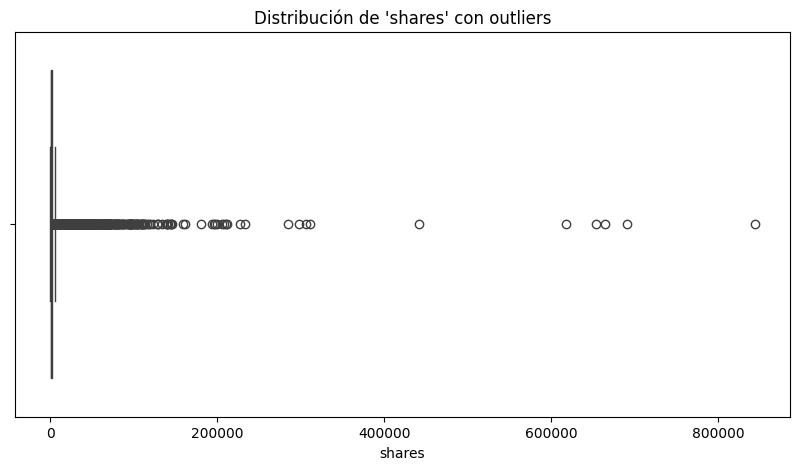

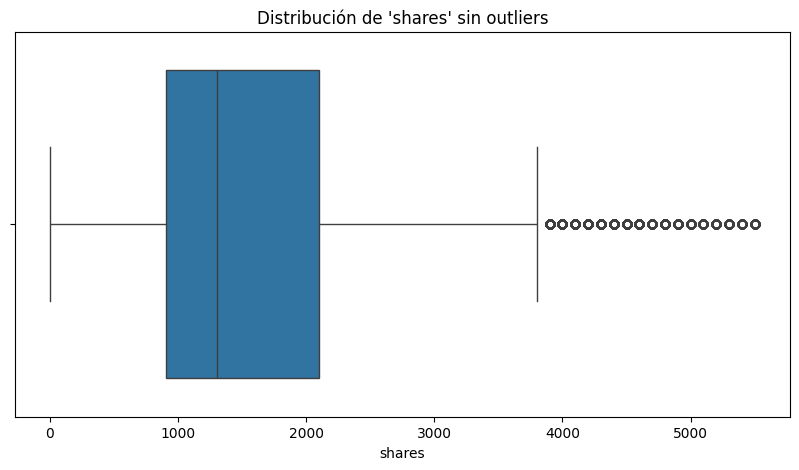

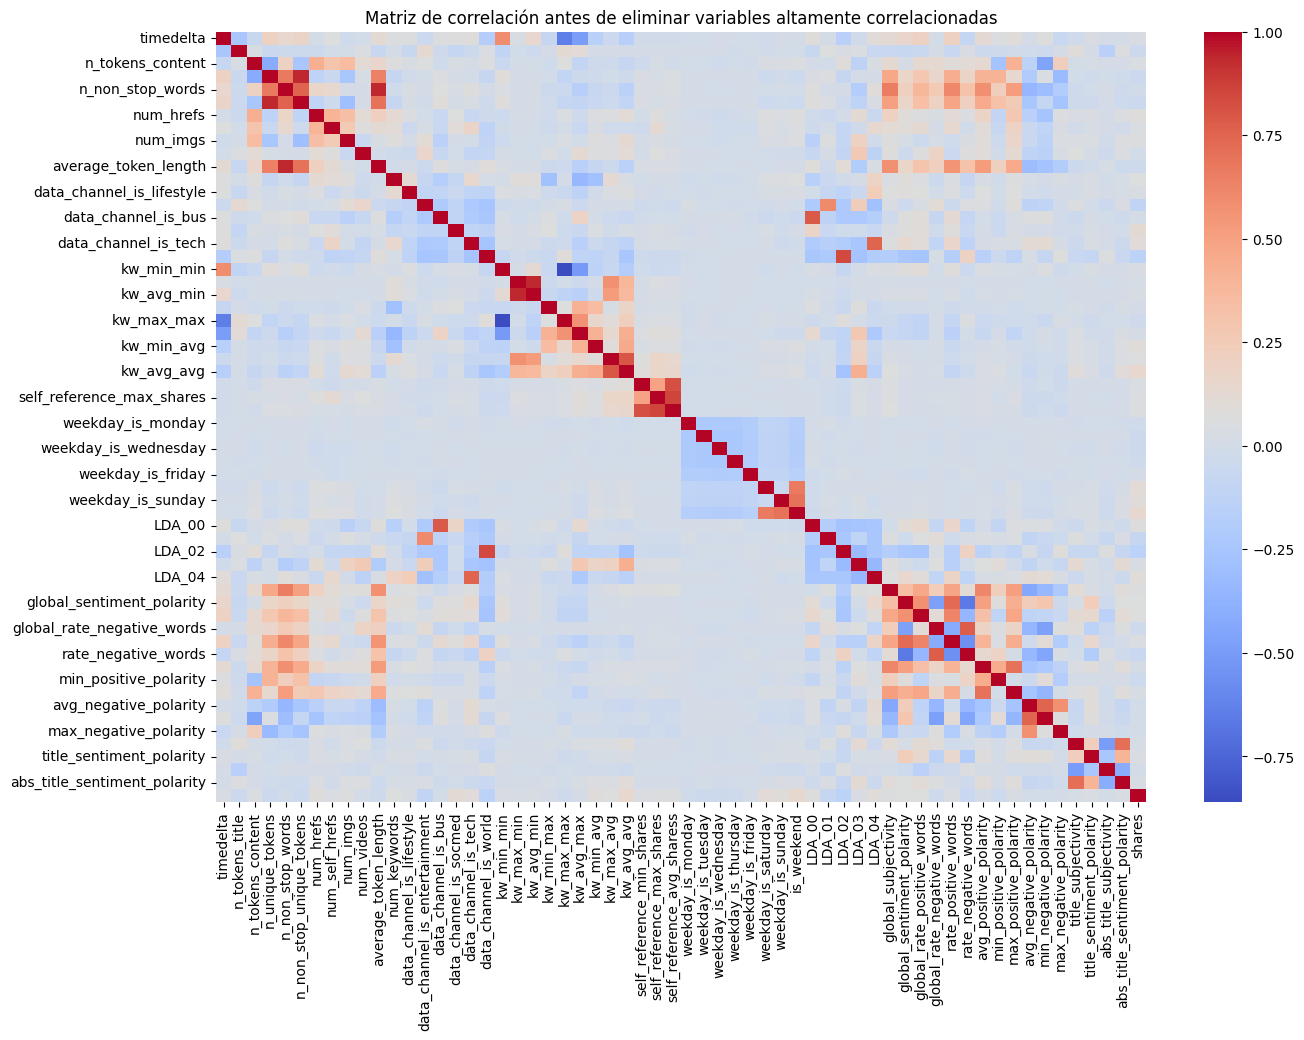

Pares de variables altamente correlacionadas:
                      Variable 1                    Variable 2  Correlation
250             n_non_stop_words          average_token_length     0.940707
185              n_unique_tokens      n_non_stop_unique_tokens     0.937128
1160                  kw_max_min                    kw_avg_min     0.934652
1709   self_reference_max_shares    self_reference_avg_sharess     0.858243
1060       data_channel_is_world                        LDA_02     0.841251
1649   self_reference_min_shares    self_reference_avg_sharess     0.819821
1526                  kw_max_avg                    kw_avg_avg     0.797421
878          data_channel_is_bus                        LDA_00     0.784441
2808  global_rate_negative_words           rate_negative_words     0.778250
245             n_non_stop_words      n_non_stop_unique_tokens     0.757132
1002        data_channel_is_tech                        LDA_04     0.750710
3173       avg_negative_polarity         m

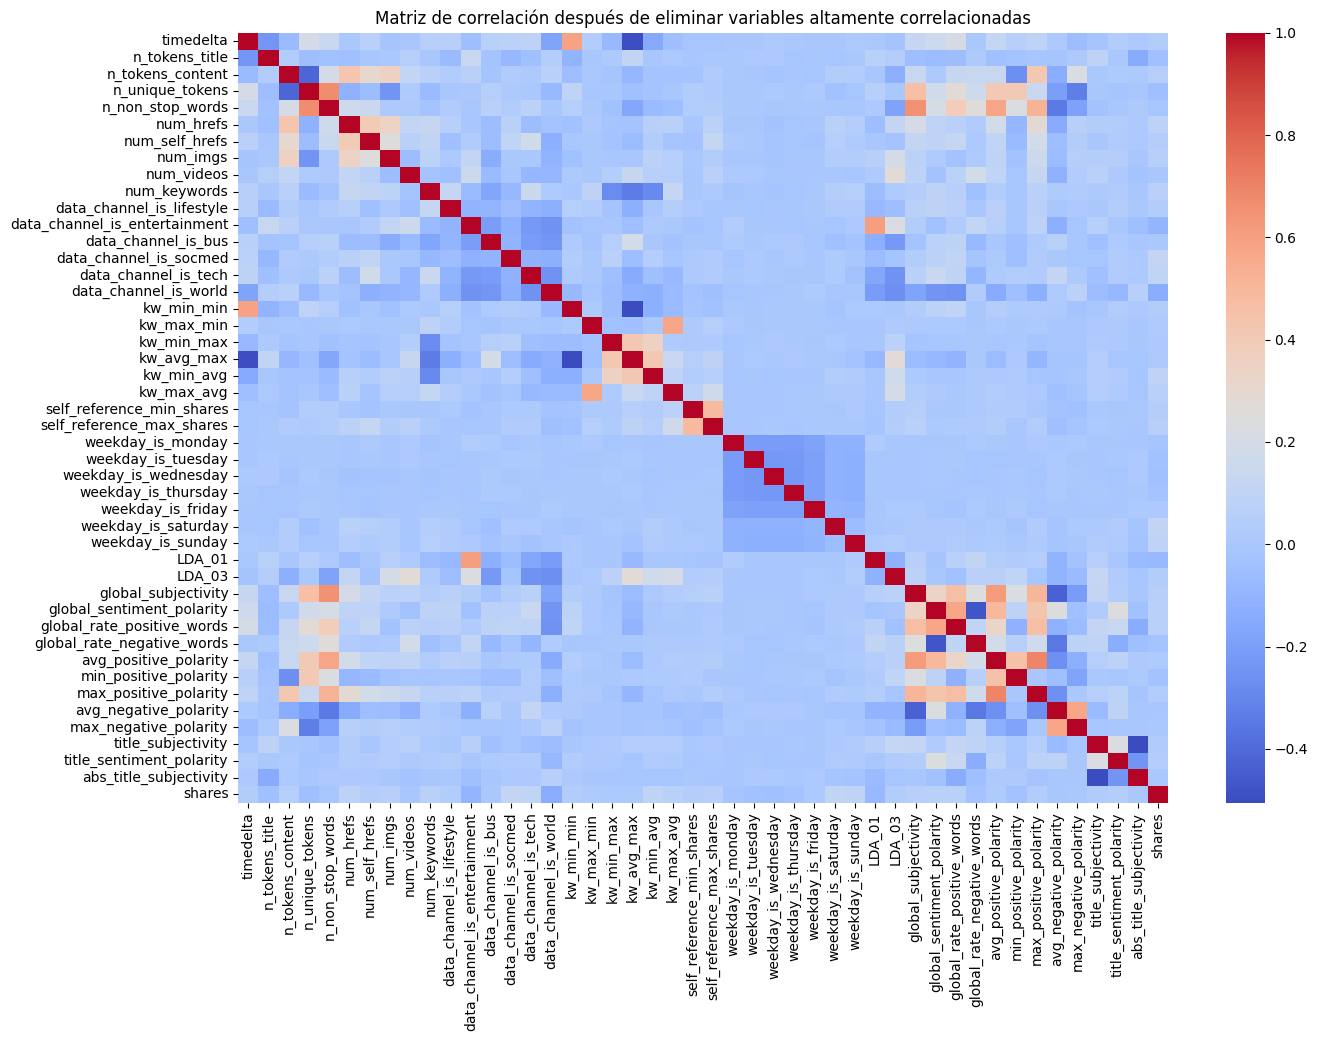

In [97]:
# Visualizar la distribución de shares con outliers
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='shares')
plt.title("Distribución de 'shares' con outliers")
plt.show()

# Detección de outliers usando IQR
q1 = df['shares'].quantile(0.25)
q3 = df['shares'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Eliminar outliers
df_no_outliers = df[(df['shares'] >= lower_bound) & (df['shares'] <= upper_bound)]

# Visualizar la distribución de shares sin outliers
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_no_outliers, x='shares')
plt.title("Distribución de 'shares' sin outliers")
plt.show()

# Calcular matriz de correlaciones
correlation_matrix = df_no_outliers.corr()

# Mostrar mapa de calor de correlaciones antes de eliminar variables
plt.figure(figsize=(15, 10))
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', fmt='.2f')
plt.title("Matriz de correlación antes de eliminar variables altamente correlacionadas")
plt.show()

# Identificar variables con correlaciones mayores a 0.7 en términos absolutos
correlated_pairs = correlation_matrix.unstack().reset_index()
correlated_pairs.columns = ['Variable 1', 'Variable 2', 'Correlation']
correlated_pairs = correlated_pairs[
    (correlated_pairs['Variable 1'] != correlated_pairs['Variable 2']) &
    (correlated_pairs['Correlation'].abs() > 0.7)
].drop_duplicates(subset=['Correlation']).sort_values(by='Correlation', ascending=False)

print("Pares de variables altamente correlacionadas:")
print(correlated_pairs)

# Eliminar una variable de cada par correlacionado
variables_to_remove = set()
for _, row in correlated_pairs.iterrows():
    if row['Variable 1'] not in variables_to_remove:
        variables_to_remove.add(row['Variable 2'])

df_reduced = df_no_outliers.drop(columns=list(variables_to_remove))

# Calcular matriz de correlaciones después de eliminar variables
reduced_correlation_matrix = df_reduced.corr()

# Mostrar mapa de calor de correlaciones después de la eliminación
plt.figure(figsize=(15, 10))
sns.heatmap(reduced_correlation_matrix, annot=False, cmap='coolwarm', fmt='.2f')
plt.title("Matriz de correlación después de eliminar variables altamente correlacionadas")
plt.show()

7. Escoge cuatro variables numéricas y analiza su distribución. Luego normaliza todas
las variables numéricas y divide los datos en entrenamiento y test (33%).

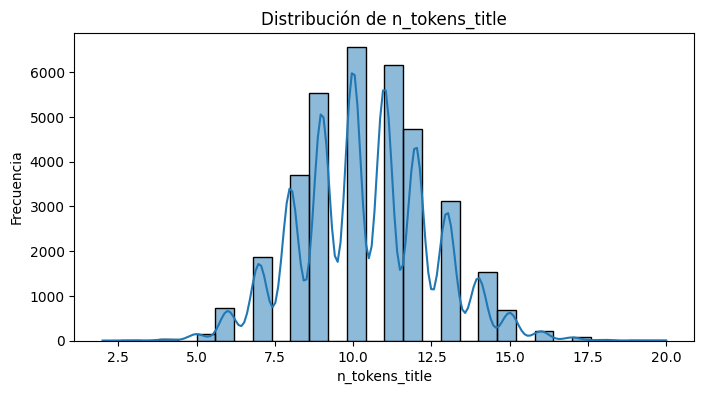

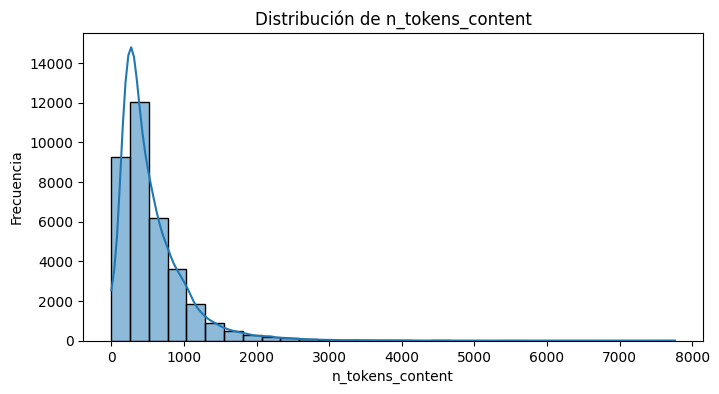

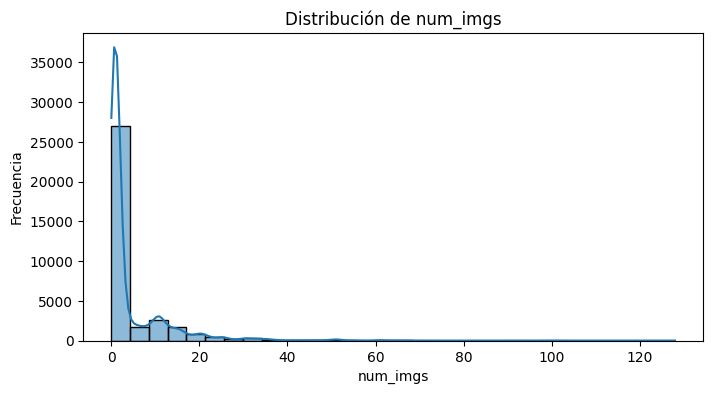

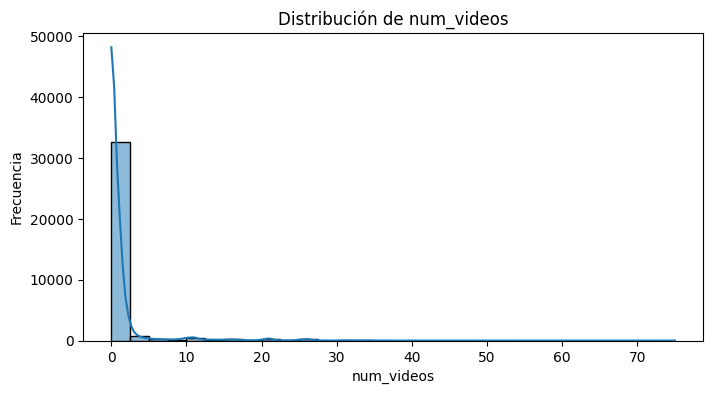

Tamaño del conjunto de entrenamiento: (23519, 60)
Tamaño del conjunto de prueba: (11584, 60)


In [99]:
# Seleccionar cuatro variables numéricas para análisis de distribución
numeric_cols = ['n_tokens_title', 'n_tokens_content', 'num_imgs', 'num_videos']  # Ejemplo de columnas
selected_data = df_no_outliers[numeric_cols]

# Análisis de distribución de las variables seleccionadas
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(selected_data[col], kde=True, bins=30)
    plt.title(f"Distribución de {col}")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.show()

# Normalización de todas las variables numéricas
scaler = MinMaxScaler()
numeric_data = df_no_outliers.select_dtypes(include=['float64', 'int64'])
normalized_data = scaler.fit_transform(numeric_data)

# Crear un DataFrame con los datos normalizados
normalized_df = pd.DataFrame(normalized_data, columns=numeric_data.columns)

# División en entrenamiento y prueba
X_train, X_test = train_test_split(normalized_df, test_size=0.33, random_state=42)

print("Tamaño del conjunto de entrenamiento:", X_train.shape)
print("Tamaño del conjunto de prueba:", X_test.shape)

8. Entrena un modelo de Random Forest usando búsqueda de grilla. La búsqueda debe
considerar:

● para n_estimators, valores entre 100 y 300 para 10 valores

● para max_depth, valores entres 2 y 15 para 10 valores

● para max_features, buscar para ‘sqrt’ y ‘log2’.
En la búsqueda de grilla considera cinco fold. Muestra los mejores hiper parámetros
encontrados por la búsqueda de grilla. Calcula dos métricas sobre el conjunto de
test, para evaluar el modelo.

X_train shape: (23519, 60)
y_train shape: (23519,)
X_test shape: (11584, 60)
y_test shape: (11584,)
Fitting 5 folds for each of 200 candidates, totalling 1000 fits
Mejores hiperparámetros: {'max_depth': 15, 'max_features': 'sqrt', 'n_estimators': 211}
MSE en conjunto de prueba: 113571.89839496817
R2 en conjunto de prueba: 0.9059535390630755


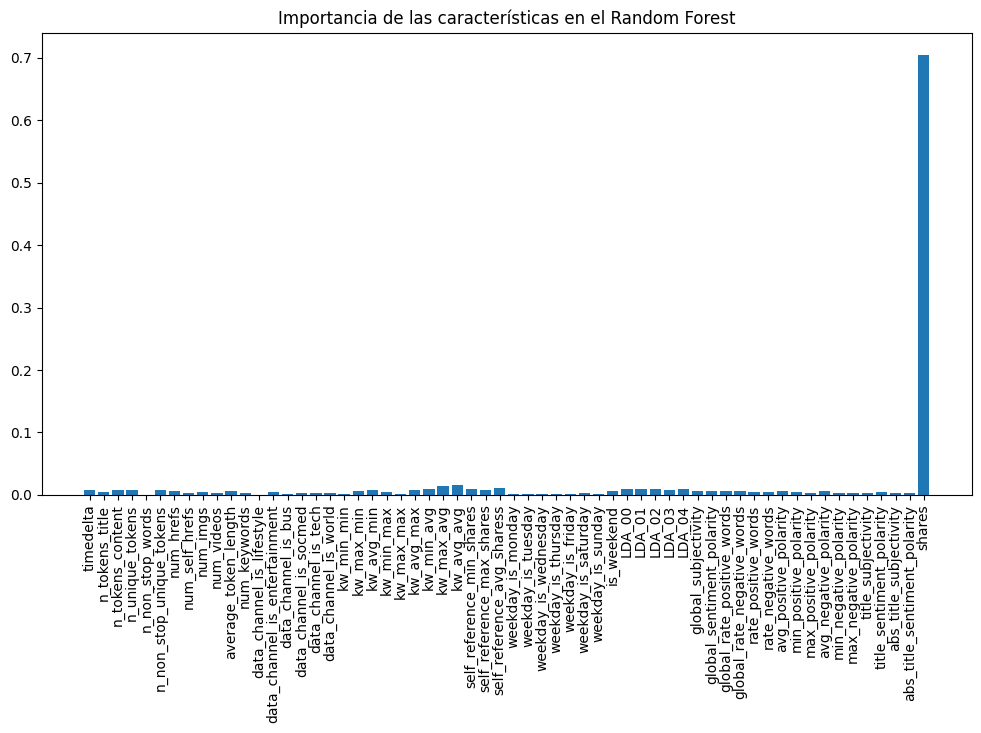

In [102]:
# Assuming 'shares' is your target variable
y = df_no_outliers['shares'] # Extract the target variable from the outlier-removed dataframe
# Reset index to avoid potential alignment issues
X_train, X_test, y_train, y_test = train_test_split(normalized_df, y.reset_index(drop=True), test_size=0.33, random_state=42)

# Print shapes to confirm consistency
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

# Parámetros para la búsqueda de grilla
param_grid = {
    'n_estimators': np.linspace(100, 300, 10, dtype=int),
    'max_depth': np.linspace(2, 15, 10, dtype=int),
    'max_features': ['sqrt', 'log2']
}

# Inicialización del modelo
rf_model = RandomForestRegressor(random_state=42)

# Configuración de Grid Search con validación cruzada de 5 folds
grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    scoring='neg_mean_squared_error',  # MSE como métrica de evaluación
    cv=5,
    verbose=1,
    n_jobs=-1
)

# Entrenamiento de Grid Search
grid_search.fit(X_train, y_train)

# Mejor modelo encontrado
best_model = grid_search.best_estimator_
best_params = grid_search.best_params_
print("Mejores hiperparámetros:", best_params)

# Predicciones en el conjunto de prueba
y_pred = best_model.predict(X_test)

# Cálculo de métricas
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE en conjunto de prueba:", mse)
print("R2 en conjunto de prueba:", r2)

# Visualización de importancia de características
importances = best_model.feature_importances_
plt.figure(figsize=(12, 6))
plt.bar(x=numeric_data.columns, height=importances)
plt.title("Importancia de las características en el Random Forest")
plt.xticks(rotation=90)
plt.show()

9. Entrena un modelo de red neuronal Fully Connected con al menos dos capas ocultas
y aplicando regularización Dropout. Utiliza en cada capa una cantidad de neuronas
mayor a 300. Calcula las mismas métricas usadas en el modelo anterior, sobre el
conjunto de test, para evaluar el modelo.

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
735/735 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - loss: 1005982.8125 - mae: 609.1982 - val_loss: 26290.4805 - val_mae: 114.4871
Epoch 2/20
735/735 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 51534.0039 - mae: 166.1002 - val_loss: 12209.0762 - val_mae: 79.5642
Epoch 3/20
735/735 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 41544.5000 - mae: 145.1632 - val_loss: 6831.3887 - val_mae: 58.1031
Epoch 4/20
735/735 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 38364.6562 - mae: 137.1051 - val_loss: 6464.4302 - val_mae: 62.7573
Epoch 5/20
735/735 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - loss: 34640.7148 - mae: 131.1104 - val_loss: 10602.8359 - val_mae: 80.1320
Epoch 6/20
735/735 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 32889.7031 - mae: 127.3407 - val_loss: 4588.7402 - val_mae: 49.4610
Epoch 7/20
735/735 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 33428.2266 - mae: 127.4182 - val_loss: 4145.4741 - val_mae: 46.1374
Epoch 8/20
735/735 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 31947.7734 - mae: 126.0211 - val_loss

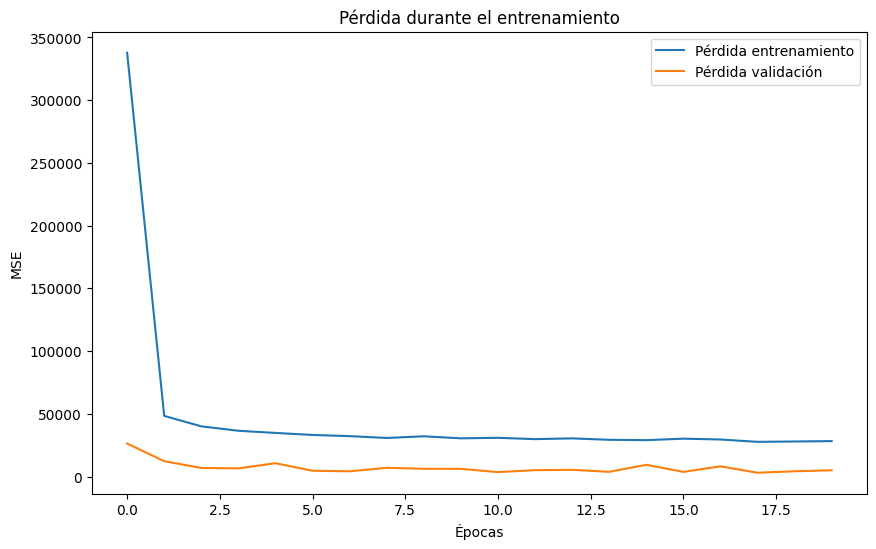

In [106]:
# Asegurarse de que los datos están normalizados
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Creación del modelo
model = Sequential([
    Dense(512, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),  # Regularización Dropout
    Dense(384, activation='relu'),
    Dropout(0.3),  # Regularización Dropout
    Dense(256, activation='relu'),
    Dropout(0.3),  # Regularización Dropout
    Dense(1, activation='linear')  # Capa de salida para regresión
])

# Compilación del modelo
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Entrenamiento
history = model.fit(
    X_train_scaled, y_train,
    validation_data=(X_test_scaled, y_test),
    epochs=20,
    batch_size=32,
    verbose=1
)

# Predicciones
y_pred = model.predict(X_test_scaled).flatten()

# Cálculo de métricas
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE en conjunto de prueba:", mse)
print("R2 en conjunto de prueba:", r2)

# Visualización de la pérdida
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Pérdida entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida validación')
plt.title('Pérdida durante el entrenamiento')
plt.xlabel('Épocas')
plt.ylabel('MSE')
plt.legend()
plt.show()

El R^2 de este modelo es de un 99%, lo que habla de un rendimiento perfecto, solo que hay que verificar que no esté sobreajustandose.

10. Implementa y entrena un modelo Extreme Gradient Boosting, usando búsqueda de
grilla con 5 fold. Para ello considera:

● n_estimators: [100, 120, 150, 200, 300]

● learning_rate: [0.008, 0.07, 0.009, 0.01, 0.02]

● subsample: np.linspace(0.05, 1, 5)

● scale_pos_weight: np.linspace(0.8, 0.9, 2)

Muestra los mejores hiper parámetros encontrados, calcula y muestra gráficamente la
importancia de las características para la predicción en el modelo. Calcula las mismas
métricas usadas en el modelo anterior, sobre el conjunto de test, para evaluar el modelo.

Fitting 5 folds for each of 250 candidates, totalling 1250 fits
Mejores hiperparámetros: {'learning_rate': 0.07, 'n_estimators': 100, 'scale_pos_weight': 0.8, 'subsample': 1.0}
MSE en conjunto de prueba: 48.378265997111356
R2 en conjunto de prueba: 0.9999599456787109


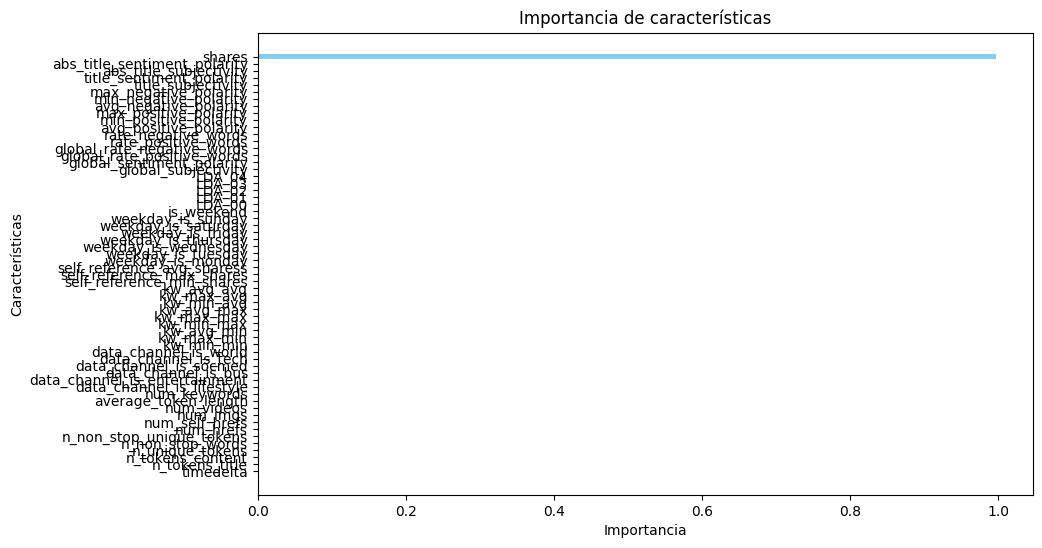

In [108]:
# Hiperparámetros para búsqueda de grilla
param_grid = {
    "n_estimators": [100, 120, 150, 200, 300],
    "learning_rate": [0.008, 0.07, 0.009, 0.01, 0.02],
    "subsample": np.linspace(0.05, 1, 5),
    "scale_pos_weight": np.linspace(0.8, 0.9, 2),
}

# Configuración del modelo base
xgb = XGBRegressor(objective="reg:squarederror", random_state=42)

# Búsqueda de grilla con 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    verbose=1,
    n_jobs=-1
)

# Entrenamiento con datos de entrenamiento
grid_search.fit(X_train_scaled, y_train)

# Mejores hiperparámetros encontrados
best_params = grid_search.best_params_
print("Mejores hiperparámetros:", best_params)

# Modelo optimizado
best_xgb = grid_search.best_estimator_

# Predicciones en el conjunto de prueba
y_pred = best_xgb.predict(X_test_scaled)

# Cálculo de métricas
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE en conjunto de prueba:", mse)
print("R2 en conjunto de prueba:", r2)

# Importancia de características
importance = best_xgb.feature_importances_
feature_names = X_train.columns  # Asumiendo que X_train es un DataFrame

# Gráfico de importancia de características
plt.figure(figsize=(10, 6))
plt.barh(feature_names, importance, color="skyblue")
plt.title("Importancia de características")
plt.xlabel("Importancia")
plt.ylabel("Características")
plt.show()

11. Construye un modelo de Bagging usando al menos tres modelos heterogéneos. Para
ello utiliza la siguiente función (utilizando el archivo entregado):
import util_bagging as ubagging
ubagging.bagging_het
Calcula las mismas métricas usadas en el modelo anterior, sobre el conjunto de test,
para evaluar el modelo.
Muestra en un DataFrame los resultados de todos los modelos y concluye.

In [117]:
# Definir modelos heterogéneos
models = [
    ("Random Forest", RandomForestRegressor(n_estimators=150, random_state=42)),
    ("Gradient Boosting", GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42)),
    ("Decision Tree", DecisionTreeRegressor(max_depth=5, random_state=42)),
]

# Construir modelo de Bagging (Voting Regressor)
bagging_model = VotingRegressor(estimators=models)

# Entrenar el modelo de Bagging
bagging_model.fit(X_train_scaled, y_train)

# Predicciones en el conjunto de prueba
y_pred = bagging_model.predict(X_test_scaled)

# Evaluación del modelo
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE del modelo Bagging:", mse)
print("R2 del modelo Bagging:", r2)

# Comparar resultados con modelos individuales
results = []

for name, model in models:
    model.fit(X_train_scaled, y_train)
    y_pred_model = model.predict(X_test_scaled)
    mse_model = mean_squared_error(y_test, y_pred_model)
    r2_model = r2_score(y_test, y_pred_model)
    results.append({"Model": name, "MSE": mse_model, "R2": r2_model})

# Agregar resultados del modelo Bagging
results.append({"Model": "Bagging (Heterogéneo)", "MSE": mse, "R2": r2})

# Mostrar resultados en un DataFrame
results_df = pd.DataFrame(results)
print(results_df)

MSE del modelo Bagging: 172.22067322789397
R2 del modelo Bagging: 0.9998573877425124
                   Model          MSE        R2
0          Random Forest     0.181965  1.000000
1      Gradient Boosting    10.264765  0.999991
2          Decision Tree  1516.744240  0.998744
3  Bagging (Heterogéneo)   172.220673  0.999857


De acuerdo con el cuadro resumen se puede ver que todos los modelos tienen un gran rendimiento, destacandose el Random Forest con un R^2 de 100%. En este sentido, es importante ver si el Random Forest se está sobreajustando o no.